## Module 2 decision trees lecture example in python

In [33]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

iris = sns.load_dataset('iris')

display(iris.info())

display(iris.describe())

display(iris.head())

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


None

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


visualizations  
1. boxplot of Sepal length grouped by species
2. matrix of scatter plots

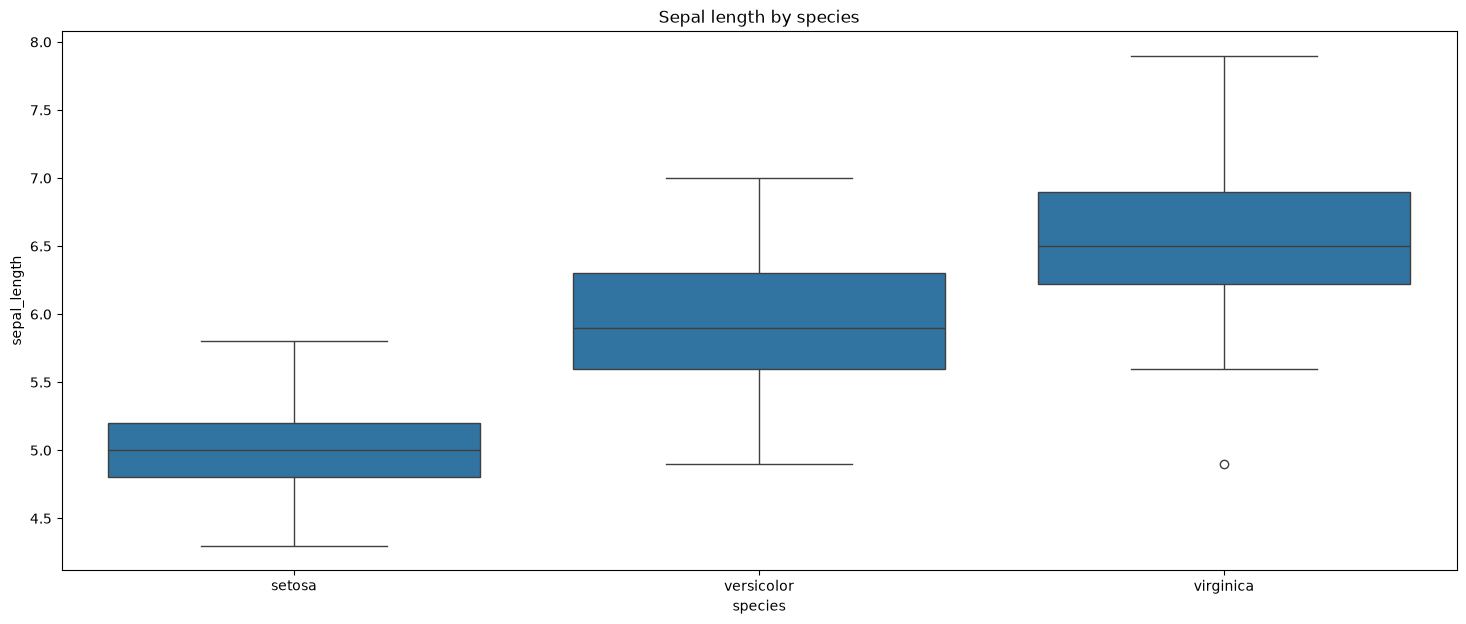

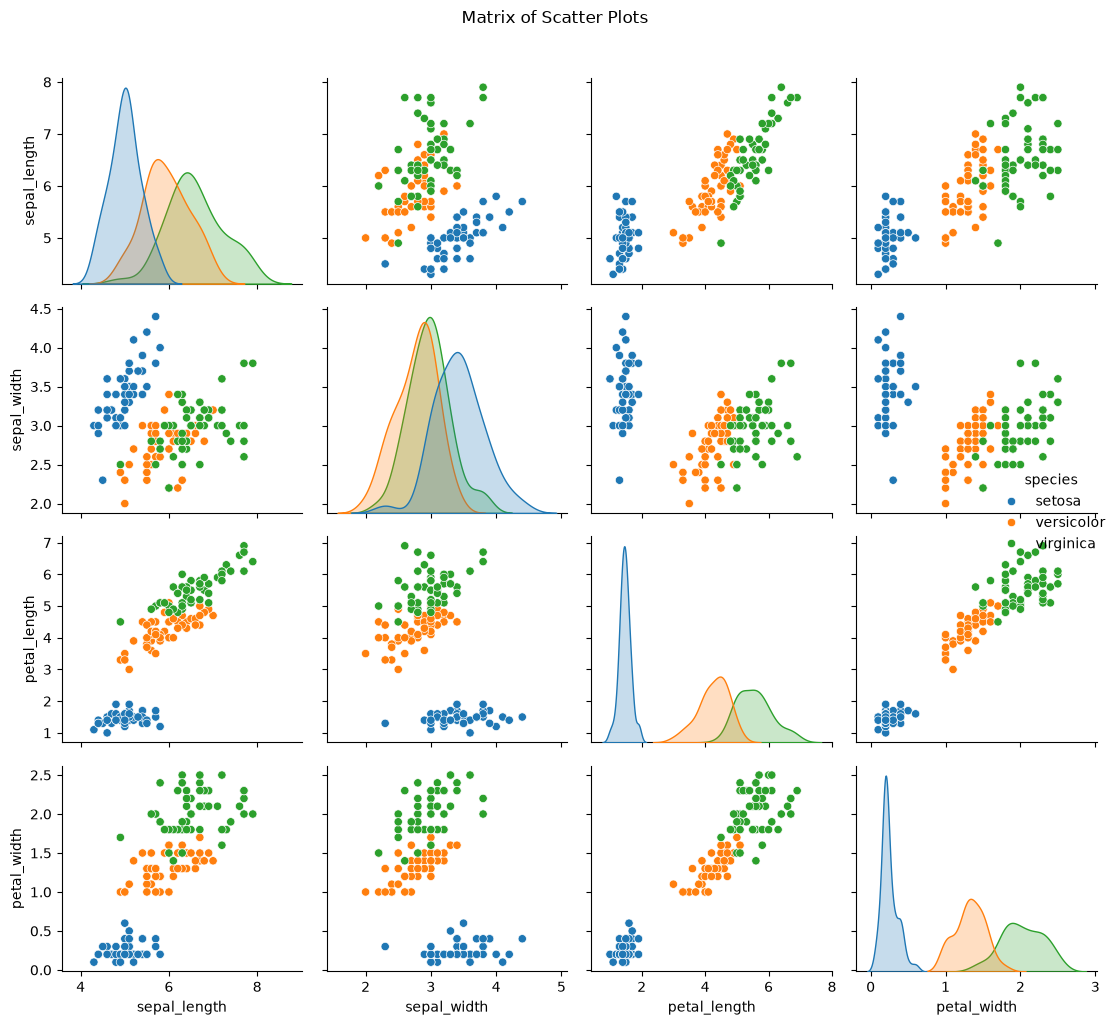

In [34]:
fig, axes = plt.subplots(1, 1, figsize=(18, 7))

ax1 = sns.boxplot(data=iris, x="species", y="sepal_length", ax=axes)
ax1.set(
    title="Sepal length by species"
)

ax2 = sns.pairplot(data=iris, hue="species")
plt.suptitle('Matrix of Scatter Plots', y=1.02)

plt.tight_layout()

## Decision Trees

Decision Tree Accuracy:  0.9333333333333333
Decision Tree confusion matrix:  [[15  0  0]
 [ 0 13  2]
 [ 0  1 14]]


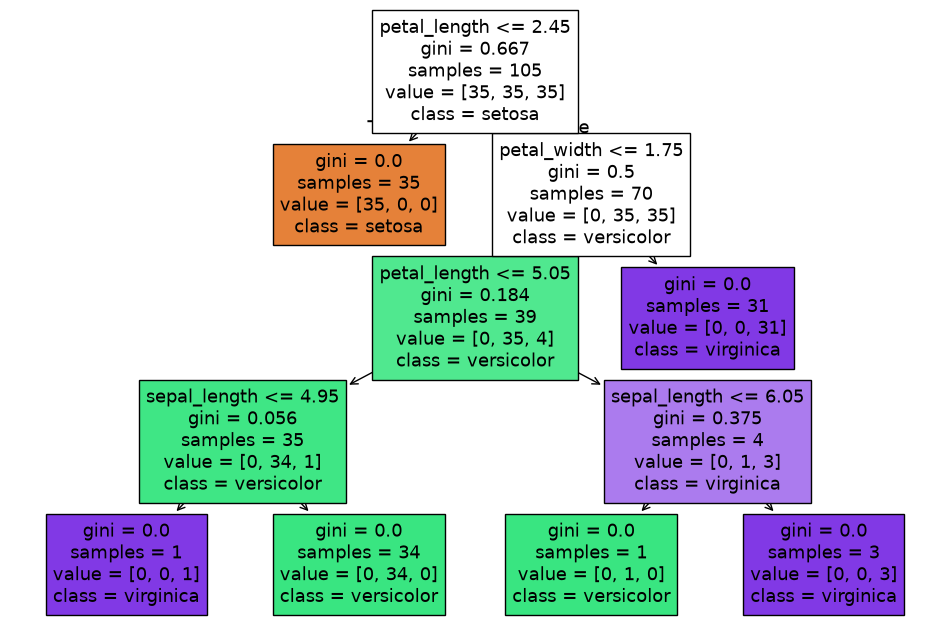


Random Forest Accuracy: 0.9555555555555556
Random Forest Confusion Matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  1 14]]


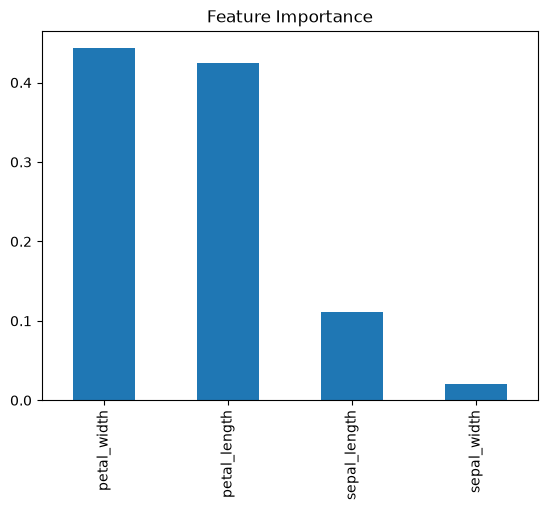

In [43]:
from sklearn.model_selection import train_test_split
from  sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

# split the feature x and the target y
x = iris.drop(columns=["species"])
y = iris["species"]


# split the data: 70% training, 30% testing
x_train, x_test, y_train, y_test = train_test_split(
    x, 
    y, 
    test_size=0.3, 
    random_state=1234, 
    stratify=y)

# decistion tree
# train the decision tree
dt_model = DecisionTreeClassifier(criterion="gini", random_state=1234, max_depth=4)
dt_model.fit(x_train, y_train)

# predict and evaluate
dt_predictions = dt_model.predict(x_test)
print("Decision Tree Accuracy: ", accuracy_score(y_test, dt_predictions))
print("Decision Tree confusion matrix: ", confusion_matrix(y_test, dt_predictions))

# visualize the tree
plt.figure(figsize=(12, 8))
plot_tree(dt_model, feature_names=x.columns, class_names=dt_model.classes_, filled=True)
plt.show()

# random forest
# Train the random forest with 100 trees
rf_model = RandomForestClassifier(n_estimators=100, random_state=1234)
rf_model.fit(x_train, y_train)

# Predict and evaluate
rf_predictions = rf_model.predict(x_test)
print("\nRandom Forest Accuracy:", accuracy_score(y_test, rf_predictions))
print("Random Forest Confusion Matrix:\n", confusion_matrix(y_test, rf_predictions))

# Display Feature Importance
feature_importances = pd.Series(rf_model.feature_importances_, index=x.columns)
feature_importances.sort_values(ascending=False).plot(kind='bar', title='Feature Importance')
plt.show()